<a href="https://colab.research.google.com/github/Phenaoj/Entregables-BIT-PaulaHenao/blob/main/taller_clustering_steam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Taller Práctico – Aprendizaje No Supervisado
## Segmentación de usuarios de Steam con clustering
**Estructura del notebook**
1. Exploración de los datos
2. Preparación de los datos
3. Modelado (K-Means como modelo principal, comparado con Jerárquico y DBSCAN)
4. Interpretación de los clusters
5. Recomendaciones de negocio

In [1]:
# Librerías
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

#Configuración estándar para todas las gráficas e imágenes
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
#pd.set_option("display.width", 200)
#pd.set_option("display.max_columns", 20)

def mostrar(nombre):
    plt.tight_layout()
    plt.show()

In [2]:
#Cargar el Dataset
from google.colab import files
uploaded = files.upload()

RUTA_DATOS = "steam-200k.csv"

Saving steam-200k.csv to steam-200k.csv


## 1. Exploración de los datos

### 1.1 Carga

El archivo **no tiene fila de encabezados**: Se asignan los nombres según la documentación
del dataset en Kaggle:

| Columna | Significado |
|---|---|
| `user_id` | Identificador del usuario |
| `game` | Nombre del juego |
| `behavior` | `purchase` (compra) o `play` (juego) |
| `value` | 1 si es compra; horas jugadas si es play |
| `extra` | Columna sin descripción en la fuente |

Se usará df_raw para los datos en crudo y df para los datos ya limpios


In [5]:
df_raw = pd.read_csv(RUTA_DATOS,header=None,
    names=["user_id", "game", "behavior", "value", "extra"],)

print("Primera vista del dataset:")
df_raw.head(10)

Primera vista del dataset:


,user_id,game,behavior,value,extra
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
1,151603712,The Elder Scrolls V Skyrim,play,273.0,0
2,151603712,Fallout 4,purchase,1.0,0
3,151603712,Fallout 4,play,87.0,0
4,151603712,Spore,purchase,1.0,0
5,151603712,Spore,play,14.9,0
6,151603712,Fallout New Vegas,purchase,1.0,0
7,151603712,Fallout New Vegas,play,12.1,0
8,151603712,Left 4 Dead 2,purchase,1.0,0
9,151603712,Left 4 Dead 2,play,8.9,0


### 1.2 Dimensiones y tipos de variables

In [6]:
print("Dimensiones (filas, columnas):", df_raw.shape)
print("\nTipos de datos:")
print(df_raw.dtypes)

Dimensiones (filas, columnas): (200000, 5)

Tipos de datos:
user_id       int64
game         object
behavior     object
value       float64
extra         int64
dtype: object


**Tipos de variables:**
- `user_id`: aparece como número, sin embargo, no se harán operaciones, solo es un identificados.

**Comportamiento de los datos:**
- Se contará los valores únicos tanto de usuarios como juegos
- Cuántas veces aparece compras y registros

In [8]:
print("Usuarios únicos:", df_raw["user_id"].nunique())
print("Juegos únicos:  ", df_raw["game"].nunique())
print("\nConteo por tipo de comportamiento:")
print(df_raw["behavior"].value_counts())

Usuarios únicos: 12393
Juegos únicos:   5155

Conteo por tipo de comportamiento:
behavior
purchase    129511
play         70489
Name: count, dtype: int64


### 1.3 Valores nulos

In [9]:
print(df_raw.isnull().sum())

user_id     0
game        0
behavior    0
value       0
extra       0
dtype: int64


### 1.4 Registros duplicados

In [12]:
# Los duplicados exáctos y a que categoría pertecene
dup_exactos = df_raw.duplicated()
print("Filas duplicadas exactas:", dup_exactos.sum())
print("\n¿De qué tipo son?")
print(df_raw[dup_exactos]["behavior"].value_counts())

Filas duplicadas exactas: 707

¿De qué tipo son?
behavior
purchase    707
Name: count, dtype: int64


- Todos los duplicados exactos son **compras**. Comprar el mismo juego dos veces en Steam
  no es posible (un juego queda en la biblioteca), así que se puede asumir como errores de registro.

### 1.5 Estadísticos descriptivos

Se calculan para horas jugadas.

In [13]:
horas = df_raw.loc[df_raw["behavior"] == "play", "value"]
print("Horas jugadas por registro (usuario-juego):")
print(horas.describe(percentiles=[.25, .5, .75, .9, .99]).round(2))
print("\nAsimetría (skewness):", round(horas.skew(), 2))

Horas jugadas por registro (usuario-juego):
count    70489.00
mean        48.88
std        229.34
min          0.10
25%          1.00
50%          4.50
75%         19.10
90%         76.00
99%        908.00
max      11754.00
Name: value, dtype: float64

Asimetría (skewness): 15.09


La media es más de 10 veces la mediana y la asimetría es muy alta.
la mayoría juega poco y unos
pocos registros tienen miles de horas.

### 1.6 Visualizaciones

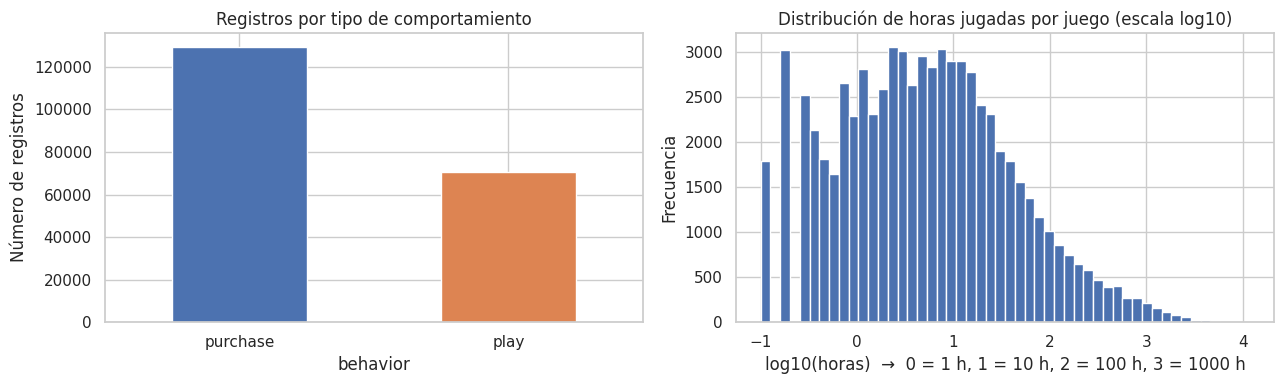

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df_raw["behavior"].value_counts().plot.bar(ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_title("Registros por tipo de comportamiento")
axes[0].set_ylabel("Número de registros")
axes[0].tick_params(axis="x", rotation=0)

axes[1].hist(np.log10(horas), bins=50, color="#4C72B0")
axes[1].set_title("Distribución de horas jugadas por juego (escala log10)")
axes[1].set_xlabel("log10(horas)  →  0 = 1 h, 1 = 10 h, 2 = 100 h, 3 = 1000 h")
axes[1].set_ylabel("Frecuencia")
mostrar("01_comportamiento_y_horas")

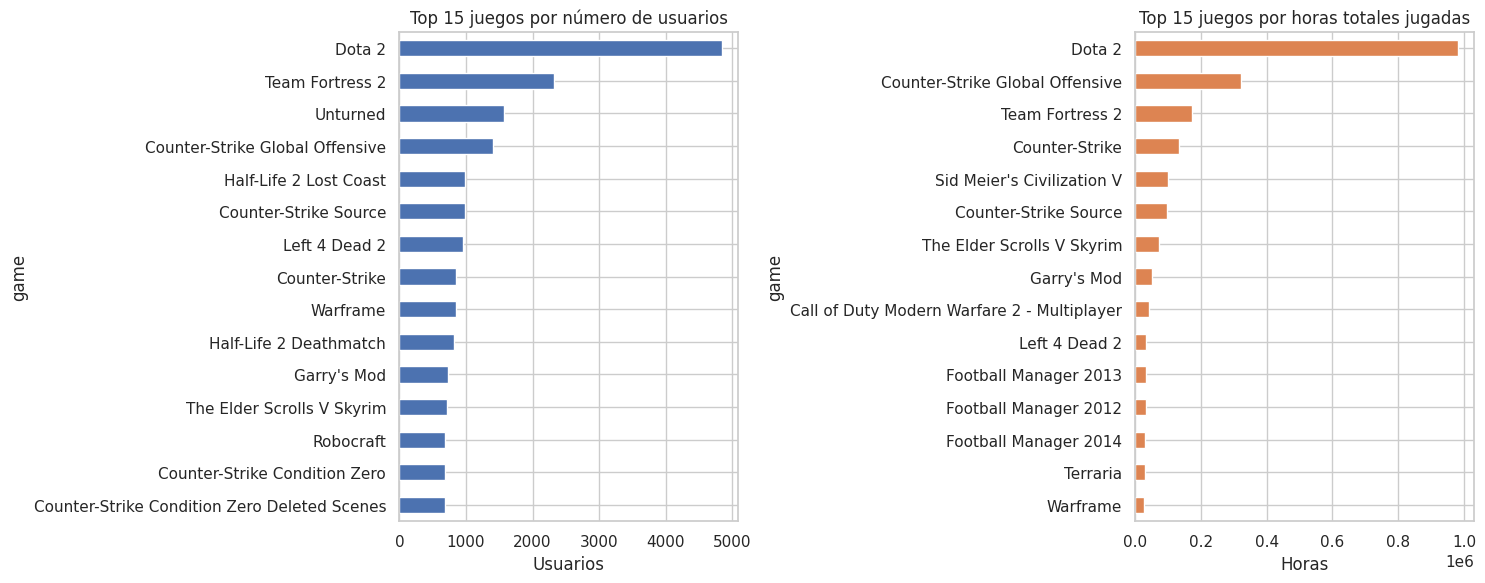

In [16]:
compras = df_raw[df_raw["behavior"] == "purchase"].drop_duplicates()
juegos_jugados = df_raw[df_raw["behavior"] == "play"]

top_compras = compras["game"].value_counts().head(15)
top_horas = juegos_jugados.groupby("game")["value"].sum().sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_compras.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 15 juegos por número de usuarios")
axes[0].set_xlabel("Usuarios")
top_horas.sort_values().plot.barh(ax=axes[1], color="#DD8452")
axes[1].set_title("Top 15 juegos por horas totales jugadas")
axes[1].set_xlabel("Horas")
mostrar("02_top_juegos")

**Observaciones:**
- Dota 2 domina tanto en usuarios como en horas.
- Los juegos competitivos y multijugador (Dota 2, Counter-Strike, Team Fortress 2) acumulan muchas horas: generan hábitos de juego largos.

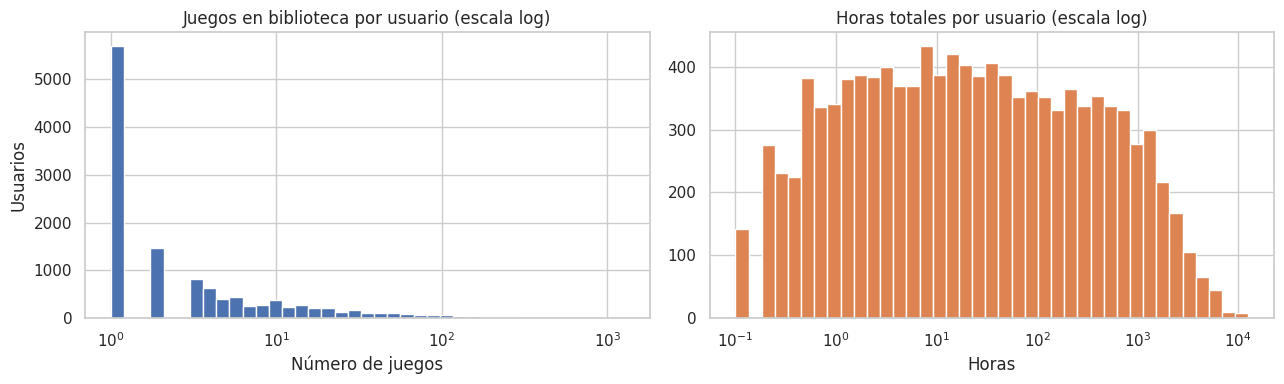

Usuarios con un solo juego: 46.0%
Usuarios que nunca jugaron nada: 8.4%


In [17]:
juegos_por_usuario = compras.groupby("user_id").size()
horas_por_usuario = juegos_jugados.groupby("user_id")["value"].sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(juegos_por_usuario, bins=np.logspace(0, 3.1, 40), color="#4C72B0")
axes[0].set_xscale("log")
axes[0].set_title("Juegos en biblioteca por usuario (escala log)")
axes[0].set_xlabel("Número de juegos")
axes[0].set_ylabel("Usuarios")

axes[1].hist(horas_por_usuario, bins=np.logspace(-1, 4.1, 40), color="#DD8452")
axes[1].set_xscale("log")
axes[1].set_title("Horas totales por usuario (escala log)")
axes[1].set_xlabel("Horas")
mostrar("03_distribuciones_por_usuario")

print(f"Usuarios con un solo juego: {(juegos_por_usuario == 1).mean():.1%}")
print(f"Usuarios que nunca jugaron nada: {1 - len(horas_por_usuario) / len(juegos_por_usuario):.1%}")

Casi la mitad de los usuarios tiene **un solo juego** y alrededor del 8 % nunca jugó.

## 2. Preparación de los datos

### 2.1 Limpieza

| Decisión | Justificación |
|---|---|
| Eliminar la columna `extra` | Es constante (siempre 0): varianza cero, no aporta nada. |
| Eliminar duplicados exactos | Son compras repetidas, imposibles en Steam: error de registro. |
| Quitar espacios al inicio y final de `game` | Evita que el mismo juego cuente como dos nombres distintos. |
|Sumar las horas con misma clave usuario-juego | Son horas reales (probablemente dos ediciones), no un error. |

In [18]:
#Eliminar Columnas Extra, los valores duplicados y los espacios en blanco
df = (df_raw.drop(columns="extra")
.drop_duplicates()
.assign(game=lambda d: d["game"].str.strip()))

#Eliminar duplicados
compras = df[df["behavior"] == "purchase"].drop_duplicates(["user_id", "game"])

#Sumar las horas
juego = (df[df["behavior"] == "play"].groupby(["user_id", "game"], as_index=False)["value"].sum().rename(columns={"value": "horas"}))

#Resultados
print("Filas originales:", len(df_raw), "→ después de limpiar:", len(df))
print("Compras únicas (usuario-juego):", len(compras))
print("Registros de juego (usuario-juego):", len(juego))

# Chequeo de consistencia: ¿hay juegos jugados que no estén comprados?
llaves_compra = set(zip(compras["user_id"], compras["game"]))
llaves_juego = set(zip(juego["user_id"], juego["game"]))
print("Juegos jugados sin registro de compra:", len(llaves_juego - llaves_compra))
print("Juegos comprados que nunca se jugaron:", len(llaves_compra - llaves_juego))

Filas originales: 200000 → después de limpiar: 199293
Compras únicas (usuario-juego): 128801
Registros de juego (usuario-juego): 70474
Juegos jugados sin registro de compra: 0
Juegos comprados que nunca se jugaron: 58327


Todos los juegos jugados tienen su compra, así que los datos son consistentes.
Además, hay muchos juegos comprados que nunca se abrieron

### 2.2 Cambio de unidad de análisis: de eventos a usuarios

El dataset original tiene una fila por **evento** (usuario + juego + comportamiento).Sin embargo, el taller pide segmentar **usuarios**, así que se construye una tabla con **una fila por usuario** y variables que describan su comportamiento

Variables candidatas:

| Variable | Qué mide |
|---|---|
| `n_comprados` | Tamaño de la biblioteca (juegos adquiridos) |
| `n_jugados` | Juegos que efectivamente jugó |
| `horas_totales` | Intensidad de uso de la plataforma |
| `horas_por_juego` | Profundidad: ¿juega mucho cada juego o poco? |
| `tasa_no_jugados` | % de juegos de su biblioteca que nunca abrió ("backlog") |
| `concentracion` | % de sus horas que se van a su juego favorito (1 = juega un solo juego) |

In [20]:
usuarios = pd.DataFrame({"n_comprados": compras.groupby("user_id").size()})

g = juego.groupby("user_id")["horas"]
usuarios["n_jugados"] = g.size()
usuarios["horas_totales"] = g.sum()
usuarios["horas_juego_top"] = g.max()
usuarios = usuarios.fillna(0)  # usuarios sin registros de juego → 0 juegos y 0 horas

usuarios["horas_por_juego"] = np.where(usuarios["n_jugados"] > 0, usuarios["horas_totales"] / usuarios["n_jugados"].replace(0, 1),0,)
usuarios["tasa_no_jugados"] = 1 - usuarios["n_jugados"] / usuarios["n_comprados"]
usuarios["concentracion"] = np.where(usuarios["horas_totales"] > 0,usuarios["horas_juego_top"] / usuarios["horas_totales"].replace(0, 1),0,)

print("Tabla de usuarios:", usuarios.shape)
usuarios.describe().T.round(2)

Tabla de usuarios: (12393, 7)


,count,mean,std,min,25%,50%,75%,max
n_comprados,12393.0,10.39,35.64,1.0,1.0,2.0,6.0,1068.0
n_jugados,12393.0,5.69,17.08,0.0,1.0,1.0,3.0,498.0
horas_totales,12393.0,278.01,760.27,0.0,1.3,13.5,155.6,11754.0
horas_juego_top,12393.0,176.16,504.76,0.0,1.2,11.6,107.0,11754.0
horas_por_juego,12393.0,74.32,283.75,0.0,1.1,7.9,39.0,11754.0
tasa_no_jugados,12393.0,0.27,0.34,0.0,0.0,0.0,0.5,1.0
concentracion,12393.0,0.78,0.33,0.0,0.6,1.0,1.0,1.0


**Decisión sobre `concentracion` para quien nunca jugó:** la división sería 0/0.
Se asignó 0 (no concentra horas en ningún juego). Es una convención que hace que
estos usuarios queden en un grupo propio

### 2.3 Transformación logarítmica

Las variables de conteo y horas tienen brechas muy grandes (hay usuarios con más de 1.000
juegos y más de 10.000 horas). K-Means usa distancias y promedios

Se aplica `log1p(x) = log(1 + x)`, que:
- comprime la cola larga y acerca la distribución a algo más simétrico,
- funciona con ceros (log(1+0) = 0), cosa que el logaritmo normal no permite.

No se elimina los datos atipicos porque los usuarios extremos (los que más compran
y más juegan) son justamente los más valiosos para el negocio. Eliminarlos sería
borrar un segmento. Con el logaritmo se conservan sin que dominen las distancias.


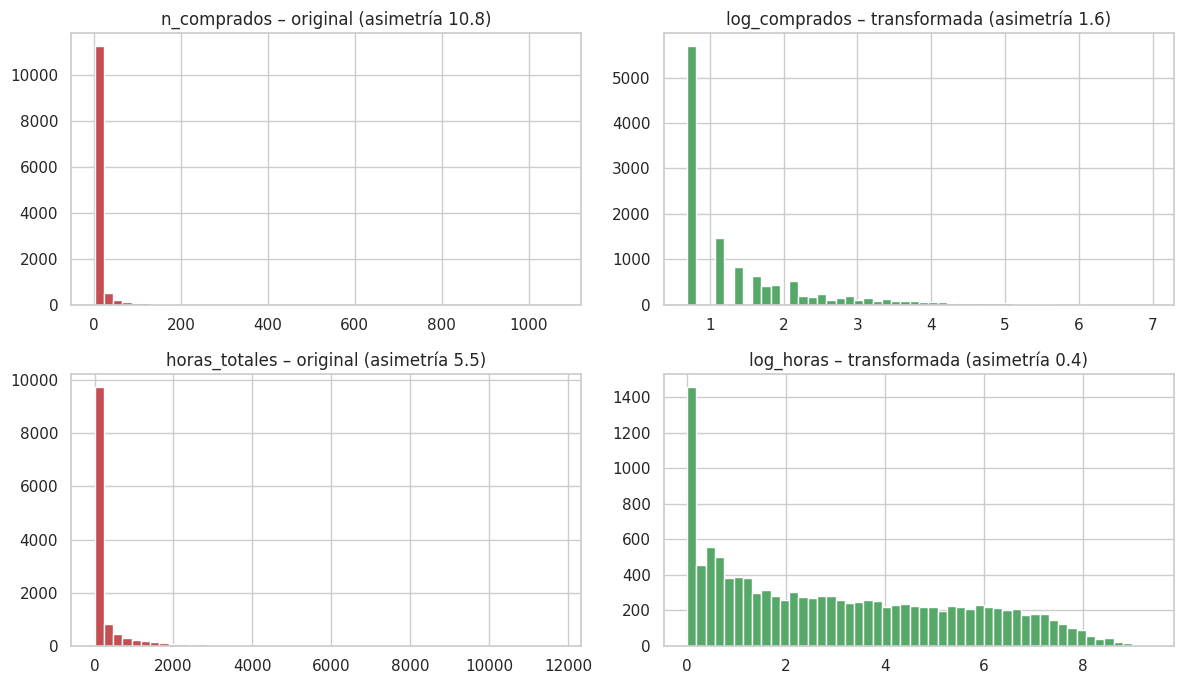

In [21]:
transformadas = pd.DataFrame(index=usuarios.index)
transformadas["log_comprados"] = np.log1p(usuarios["n_comprados"])
transformadas["log_jugados"] = np.log1p(usuarios["n_jugados"])
transformadas["log_horas"] = np.log1p(usuarios["horas_totales"])
transformadas["log_horas_por_juego"] = np.log1p(usuarios["horas_por_juego"])
transformadas["tasa_no_jugados"] = usuarios["tasa_no_jugados"]
transformadas["concentracion"] = usuarios["concentracion"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, (orig, trans) in enumerate([("n_comprados", "log_comprados"), ("horas_totales", "log_horas")]):
    axes[i, 0].hist(usuarios[orig], bins=50, color="#C44E52")
    axes[i, 0].set_title(f"{orig} – original (asimetría {usuarios[orig].skew():.1f})")
    axes[i, 1].hist(transformadas[trans], bins=50, color="#55A868")
    axes[i, 1].set_title(f"{trans} – transformada (asimetría {transformadas[trans].skew():.1f})")
mostrar("04_antes_despues_log")

### 2.4 Selección de variables: revisión de correlaciones

Dos variables miden casi lo mismo, incluir ambas hace que ese aspecto pese el doble
en la distancia, lo que sesga el clustering. Se revisa la matriz de correlación.

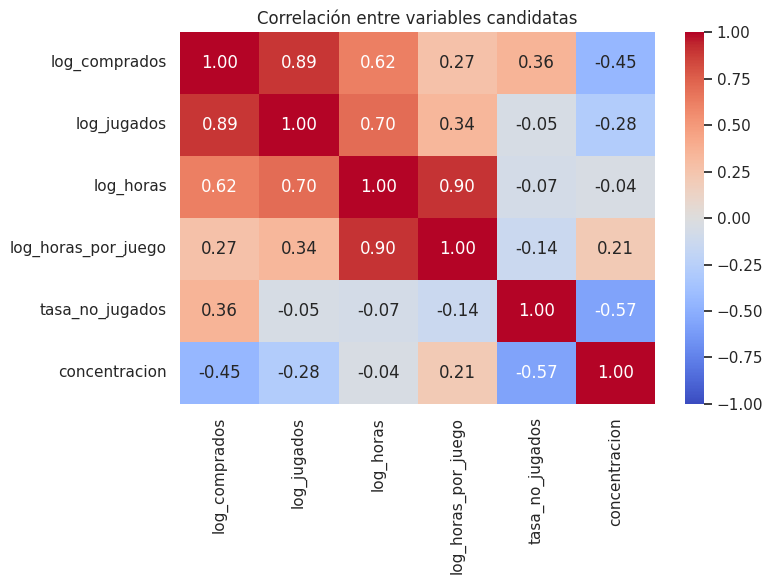

In [22]:
plt.figure(figsize=(8, 6))
sns.heatmap(transformadas.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables candidatas")
mostrar("05_correlaciones")

**Decisiones de selección:**
- `log_jugados` tiene una correlación de ~0,89 con `log_comprados`: es casi redundante.
  Además, la información de "cuántos compra vs. cuántos juega" ya la captura
  `tasa_no_jugados`. **Se descarta.**
- `log_horas_por_juego` tiene una correlación de ~0,90 con `log_horas`. **Se descarta.**

**Variables finales (4):**
1. `log_comprados` → tamaño de biblioteca (comportamiento de compra)
2. `log_horas` → intensidad de juego
3. `tasa_no_jugados` → ¿compra más de lo que juega?
4. `concentracion` → ¿se dedica a un solo juego o diversifica?

Cubren cuatro dimensiones distintas del comportamiento.

In [24]:
VARIABLES = ["log_comprados", "log_horas", "tasa_no_jugados", "concentracion"]
X = transformadas[VARIABLES]

### 2.5 Escalado (estandarización)

Sin escalar, las horas dominarían la distancia solo por tener números más grandes.
Con `StandardScaler` cada variable queda con media 0 y desviación estándar 1,
de modo que todas pesan lo mismo.

In [25]:
escalador = StandardScaler()
X_esc = escalador.fit_transform(X)
pd.DataFrame(X_esc, columns=VARIABLES).describe().round(2)

,log_comprados,log_horas,tasa_no_jugados,concentracion
count,12393.00,12393.00,12393.00,12393.00
mean,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00
min,-0.74,-1.26,-0.79,-2.37
25%,-0.74,-0.92,-0.79,-0.55
50%,-0.36,-0.16,-0.79,0.67
75%,0.44,0.82,0.66,0.67
max,5.17,2.59,2.11,0.67


## 3. Modelado

### 3.1 Elección de algoritmos

- **K-Means (modelo principal):** escala muy bien a ~12.400 usuarios, es fácil de
  interpretar y es el estándar
  para segmentación de clientes.

### 3.2 K-Means: elección del número de clusters (k)


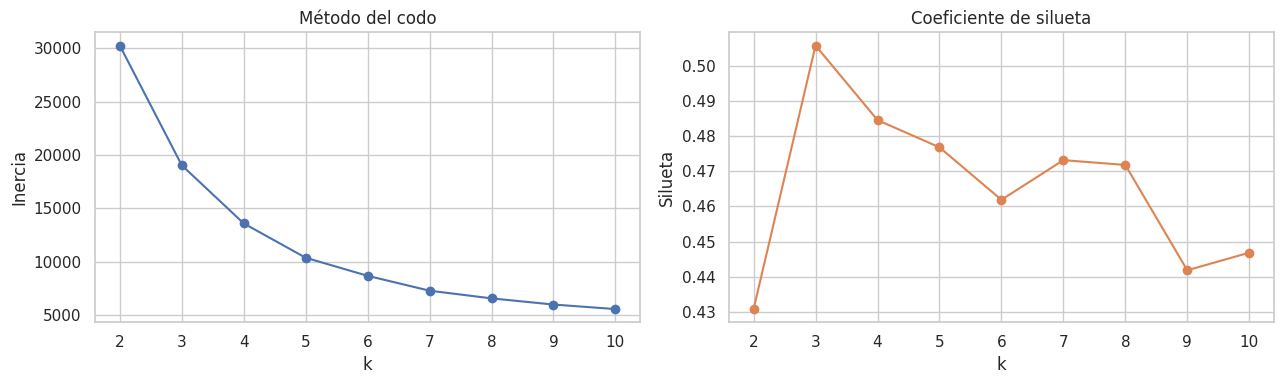

,k,inercia,silueta
0,2,30268.0,0.431
1,3,19040.0,0.506
2,4,13583.0,0.485
3,5,10364.0,0.477
4,6,8667.0,0.462
5,7,7272.0,0.473
6,8,6551.0,0.472
7,9,5972.0,0.442
8,10,5547.0,0.447


In [27]:
SEMILLA = 42
rango_k = range(2, 11)
inercias, siluetas = [], []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = km.fit_predict(X_esc)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_esc, etiquetas, sample_size=5000, random_state=SEMILLA))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(rango_k), inercias, "o-")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inercia")
axes[1].plot(list(rango_k), siluetas, "o-", color="#DD8452")
axes[1].set_title("Coeficiente de silueta")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silueta")
mostrar("06_codo_silueta")

pd.DataFrame({"k": list(rango_k), "inercia": np.round(inercias), "silueta": np.round(siluetas, 3)})

**Elección de k = 5. Justificación:**

Matemáticamente, k = 3 tiene la silueta más alta (~0,50). Pero al revisar los perfiles con
k = 3, el cluster más grande mezcla a usuarios que jugaron **2 horas** con usuarios que
jugaron **cientos de horas** en uno o dos juegos. Para el negocio son personas totalmente
distintas (una está a punto de irse y la otra es fiel).

Con k = 5 la silueta baja muy poco (~0,47, una diferencia pequeña), la inercia ya se
encuentra en la zona donde el codo se aplana, y los grupos se pueden accionar. Se
prefiere **perder un poco de separación matemática a cambio de segmentos útiles**


In [28]:
# Evidencia de por qué no k = 3: perfil del cluster más grande con k = 3
etiq_k3 = KMeans(n_clusters=3, n_init=10, random_state=SEMILLA).fit_predict(X_esc)
mayor_k3 = pd.Series(etiq_k3).value_counts().idxmax()
horas_mayor = usuarios.loc[etiq_k3 == mayor_k3, "horas_totales"]
print(f"Cluster más grande con k=3: {len(horas_mayor)} usuarios")
print("Percentiles de horas totales dentro de ese cluster:")
print(horas_mayor.quantile([.1, .25, .5, .75, .9]).round(1))

Cluster más grande con k=3: 7791 usuarios
Percentiles de horas totales dentro de ese cluster:
0.10      0.4
0.25      1.2
0.50      5.7
0.75     31.0
0.90    142.0
Name: horas_totales, dtype: float64


Dentro de un mismo cluster con k = 3 conviven usuarios con muy pocas horas y usuarios
con cientos de horas. Esto confirma que k = 3 es demasiado grueso para el negocio.

In [29]:
K = 5
kmeans = KMeans(n_clusters=K, n_init=20, random_state=SEMILLA)
usuarios["cluster"] = kmeans.fit_predict(X_esc)
print("Silueta final (muestra de 5.000):",
      round(silhouette_score(X_esc, usuarios["cluster"], sample_size=5000, random_state=SEMILLA), 3))
usuarios["cluster"].value_counts().sort_index()

Silueta final (muestra de 5.000): 0.477


,count
cluster,
0,2342
1,4502
2,1047
3,1969
4,2533


3.3 Visualización de los clusters (PCA)

Para ver 4 dimensiones en un plano se usa PCA con 2 componentes. Es solo para visualizar;
el clustering se hizo con las 4 variables.

In [32]:
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X_esc)
print("Varianza explicada por los 2 componentes:", round(pca.explained_variance_ratio_.sum() * 100, 1), "%")

Varianza explicada por los 2 componentes: 83.6 %


## 4. Interpretación de los clusters

### 4.1 Perfil de cada cluster

Se usan **medianas** además de medias, porque con distribuciones tan asimétricas la media
se distorsiona por los usuarios extremos.

In [33]:
perfil = usuarios.groupby("cluster").agg(
    usuarios=("n_comprados", "size"),
    juegos_mediana=("n_comprados", "median"),
    juegos_media=("n_comprados", "mean"),
    jugados_mediana=("n_jugados", "median"),
    horas_mediana=("horas_totales", "median"),
    horas_media=("horas_totales", "mean"),
    pct_no_jugados=("tasa_no_jugados", "mean"),
    concentracion=("concentracion", "mean"),
)
perfil["% usuarios"] = (perfil["usuarios"] / perfil["usuarios"].sum() * 100)
perfil["% horas totales"] = (usuarios.groupby("cluster")["horas_totales"].sum()
                             / usuarios["horas_totales"].sum() * 100)
perfil.round(2)

,usuarios,juegos_mediana,juegos_media,jugados_mediana,horas_mediana,horas_media,pct_no_jugados,concentracion,% usuarios,% horas totales
cluster,,,,,,,,,,
0,2342,4.0,5.54,1.0,12.1,94.75,0.61,0.91,18.90,6.44
1,4502,1.0,1.12,1.0,2.3,5.51,0.00,0.98,36.33,0.72
2,1047,1.0,2.54,0.0,0.0,0.00,1.00,0.00,8.45,0.00
3,1969,26.0,51.20,16.0,618.3,1101.70,0.37,0.45,15.89,62.96
4,2533,2.0,2.89,2.0,139.8,406.39,0.07,0.88,20.44,29.88


### 4.2 Asignación de nombres

K-Means numera los clusters de forma arbitraria. Para que los nombres no dependan de
esa numeración, se asignan con reglas basadas en el perfil:
- **Inactivos:** el cluster con menos horas (prácticamente 0).
- **Coleccionistas Hardcore:** el que tiene la biblioteca más grande.
- De los tres restantes:
  - **Acumuladores:** el de mayor % de juegos sin jugar.
  - **Jugadores Dedicados:** el de más horas.
  - **Jugadores Casuales:** el que queda (pocas horas, 1 juego).

In [34]:
restantes = list(perfil.index)
nombres = {}

c = perfil.loc[restantes, "horas_media"].idxmin()
nombres[c] = "Inactivos"
restantes.remove(c)

c = perfil.loc[restantes, "juegos_media"].idxmax()
nombres[c] = "Coleccionistas Hardcore"
restantes.remove(c)

c = perfil.loc[restantes, "pct_no_jugados"].idxmax()
nombres[c] = "Acumuladores"
restantes.remove(c)

c = perfil.loc[restantes, "horas_mediana"].idxmax()
nombres[c] = "Jugadores Dedicados"
restantes.remove(c)

nombres[restantes[0]] = "Jugadores Casuales"

usuarios["segmento"] = usuarios["cluster"].map(nombres)
perfil.insert(0, "segmento", perfil.index.map(nombres))

orden = ["Inactivos", "Jugadores Casuales", "Acumuladores", "Jugadores Dedicados", "Coleccionistas Hardcore"]
perfil_seg = perfil.set_index("segmento").loc[orden]
perfil_seg.round(2)

,usuarios,juegos_mediana,juegos_media,jugados_mediana,horas_mediana,horas_media,pct_no_jugados,concentracion,% usuarios,% horas totales
segmento,,,,,,,,,,
Inactivos,1047,1.0,2.54,0.0,0.0,0.00,1.00,0.00,8.45,0.00
Jugadores Casuales,4502,1.0,1.12,1.0,2.3,5.51,0.00,0.98,36.33,0.72
Acumuladores,2342,4.0,5.54,1.0,12.1,94.75,0.61,0.91,18.90,6.44
Jugadores Dedicados,2533,2.0,2.89,2.0,139.8,406.39,0.07,0.88,20.44,29.88
Coleccionistas Hardcore,1969,26.0,51.20,16.0,618.3,1101.70,0.37,0.45,15.89,62.96


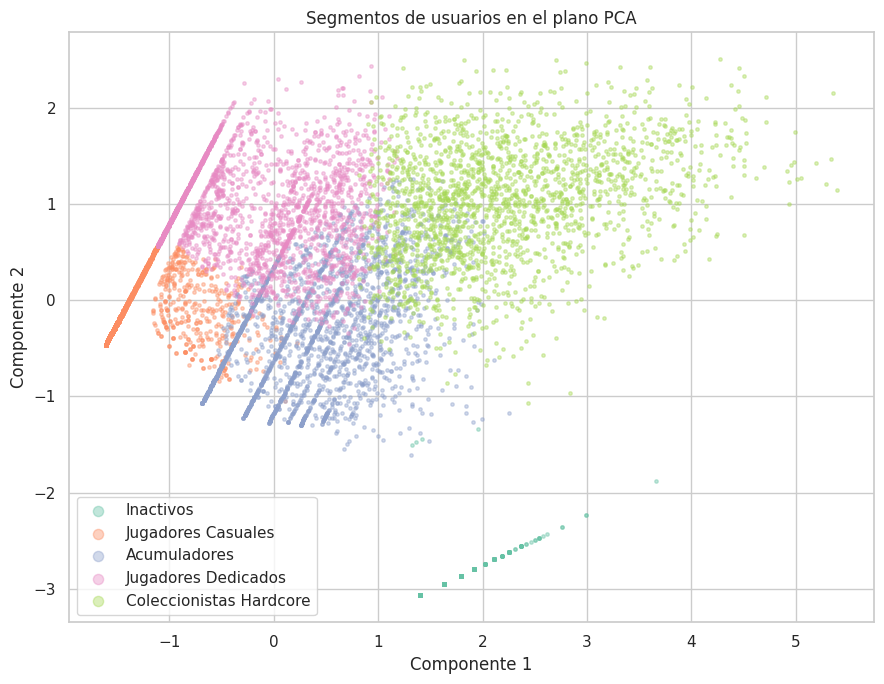

In [35]:
paleta = dict(zip(orden, sns.color_palette("Set2", len(orden))))

plt.figure(figsize=(9, 7))
for seg in orden:
    m = (usuarios["segmento"] == seg).values
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=6, alpha=0.4, label=seg, color=paleta[seg])
plt.title("Segmentos de usuarios en el plano PCA")
plt.xlabel("Componente 1")
plt.ylabel("Componente 2")
plt.legend(markerscale=3)
mostrar("09_clusters_pca")

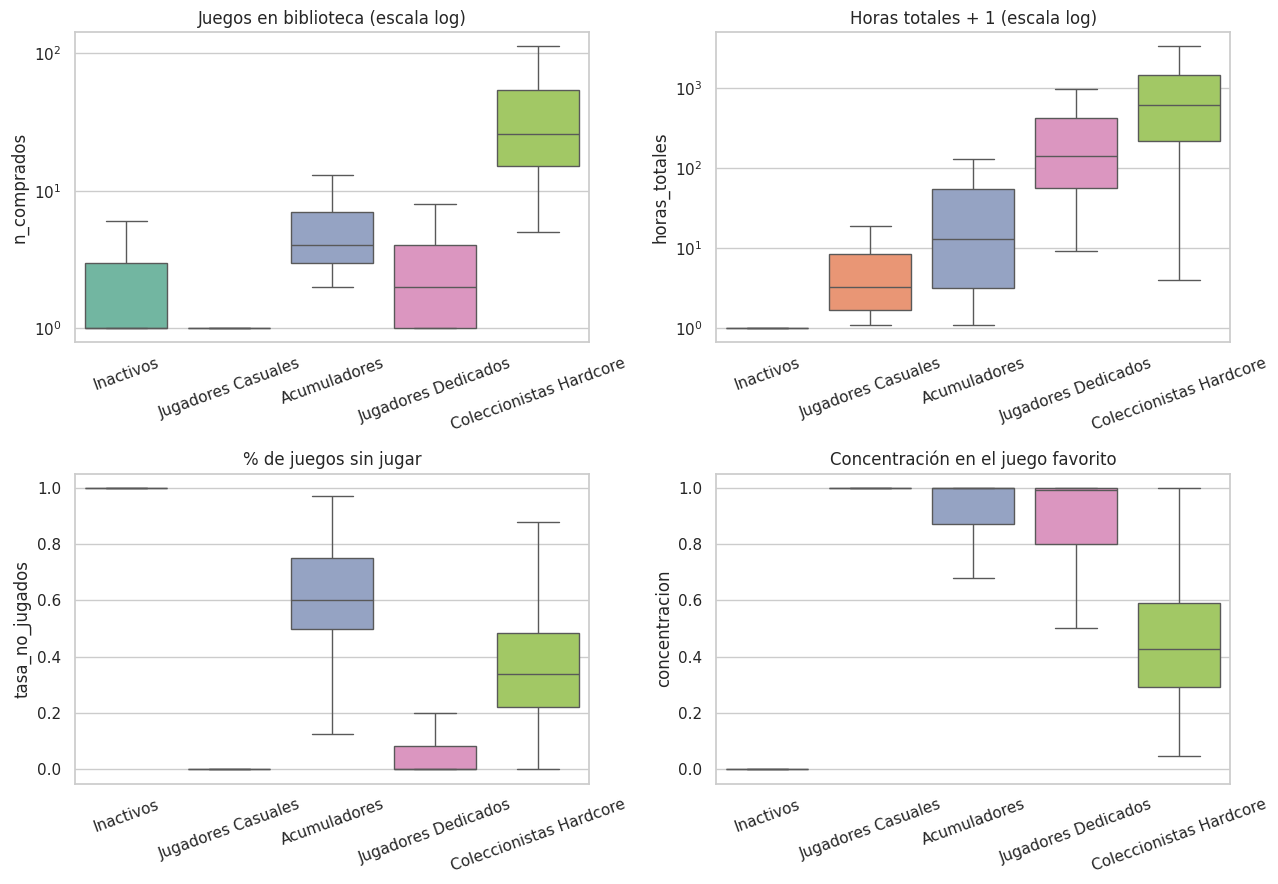

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, var, titulo in zip(
    axes.ravel(),
    ["n_comprados", "horas_totales", "tasa_no_jugados", "concentracion"],
    ["Juegos en biblioteca (escala log)", "Horas totales + 1 (escala log)", "% de juegos sin jugar", "Concentración en el juego favorito"],
):
    # A las horas se les suma 1 para poder usar escala log con usuarios de 0 horas
    datos = usuarios[var] + (1 if var == "horas_totales" else 0)
    sns.boxplot(x=usuarios["segmento"], y=datos, order=orden, palette=paleta, ax=ax, showfliers=False)
    if var in ["n_comprados", "horas_totales"]:
        ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
mostrar("10_boxplots_segmentos")

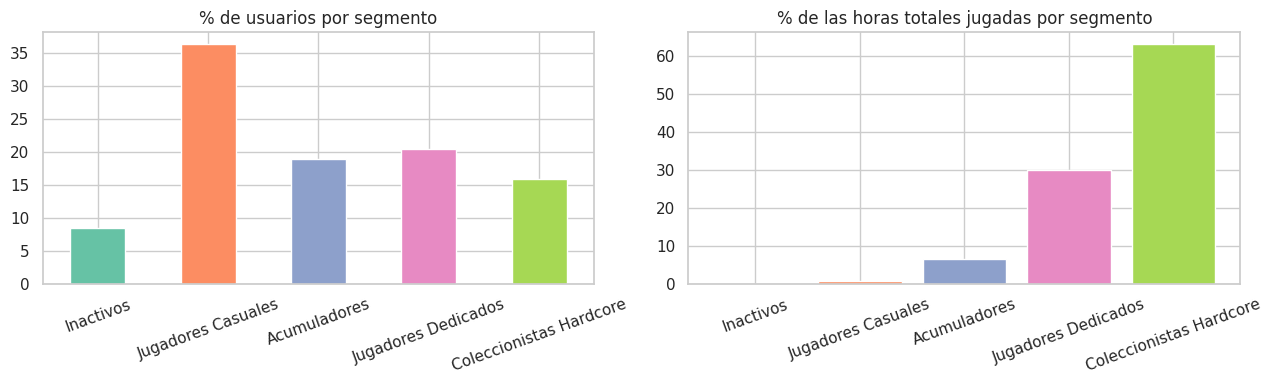

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
perfil_seg["% usuarios"].plot.bar(ax=axes[0], color=[paleta[s] for s in orden])
axes[0].set_title("% de usuarios por segmento")
axes[1].bar(orden, perfil_seg["% horas totales"], color=[paleta[s] for s in orden])
axes[1].set_title("% de las horas totales jugadas por segmento")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.set_xlabel("")
mostrar("11_peso_segmentos")

In [39]:
# Juegos más frecuentes en la biblioteca de cada segmento
compras_seg = compras.merge(usuarios[["segmento"]], left_on="user_id", right_index=True)
for seg in orden:
    top = compras_seg.loc[compras_seg["segmento"] == seg, "game"].value_counts().head(5)
    n_seg = (usuarios["segmento"] == seg).sum()
    print(f"\n{seg} ({n_seg} usuarios) – juegos más comunes:")
    for juego_nombre, n in top.items():
        print(f"   {juego_nombre:<45} {n / n_seg:6.1%} de los usuarios")


Inactivos (1047 usuarios) – juegos más comunes:
   Half-Life 2 Lost Coast                         10.8% de los usuarios
   Unturned                                       10.6% de los usuarios
   Half-Life 2 Deathmatch                         10.5% de los usuarios
   Counter-Strike                                  6.9% de los usuarios
   Counter-Strike Source                           6.1% de los usuarios

Jugadores Casuales (4502 usuarios) – juegos más comunes:
   Dota 2                                         52.6% de los usuarios
   Team Fortress 2                                13.4% de los usuarios
   Unturned                                        4.2% de los usuarios
   Counter-Strike Global Offensive                 1.5% de los usuarios
   Sid Meier's Civilization V                      1.1% de los usuarios

Acumuladores (2342 usuarios) – juegos más comunes:
   Dota 2                                         26.8% de los usuarios
   Unturned                                      

### 4.3 Descripción de los segmentos

**1. Inactivos (~8 % de los usuarios)**
- Tienen 1 a 3 juegos y **nunca jugaron ninguno** (0 horas).
  **hipótesis**: sin precios no se puede confirmar.
- ¿Ocasionales o frecuentes? Ninguno de los dos: **no son jugadores activos**.

**2. Jugadores Casuales (~36 %, el grupo más grande)**
- Exactamente 1 juego, lo jugaron, pero muy poco (mediana de ~2 horas).
- Dominan Dota 2 y Team Fortress 2: Muchos lo probaron y lo dejaron.
- Son **jugadores ocasionales**. Compran poco o nada.

**3. Acumuladores (~19 %)**
- Tienen una biblioteca pequeña o mediana (mediana de ~4 juegos), pero **más de la mitad
  de sus juegos nunca los abrieron**. Juegan principalmente uno (alta concentración).
- Ocasionales a moderados. **Compran más de lo que juegan.**

**4. Jugadores Dedicados (~20 %)**
- Pocos juegos (mediana de ~2), casi todos jugados, y **muchas horas** (mediana >100 h).
- Alta concentración: son fieles a uno o dos títulos, sobre todo competitivos
  (Dota 2, Counter-Strike).
- **Jugadores frecuentes, pero compradores poco frecuentes.** Su valor está en el
  tiempo dentro del juego, no en comprar más juegos.

**5. Coleccionistas Hardcore (~16 %)**
- Bibliotecas grandes (mediana de ~26 juegos, algunos con cientos), muchas horas
  (mediana >600 h) y **las horas repartidas** en muchos juegos (baja concentración).
- Aun así, alrededor de un tercio de su biblioteca no lo han jugado.
- Son el grupo **más valioso**: siendo ~16 % de los usuarios, acumulan ~63 % de todas
  las horas jugadas.
- **Jugadores y compradores frecuentes.**

### 4.4 Diferencias clave entre clusters

Los segmentos se separan en dos ejes:
- **Eje de compra** (cuántos juegos tiene): Casuales/Inactivos (1) → Dedicados (2) →
  Acumuladores (4) → Coleccionistas (26+).
- **Eje de uso** (cuántas horas y en qué): Inactivos (0 h) → Casuales (pocas horas) →
  Dedicados (muchas horas en un juego) → Coleccionistas (muchas horas en muchos juegos).

El contraste más interesante es **Acumuladores vs. Dedicados**: los primeros compran
más pero juegan menos, y los segundos compran poco pero juegan mucho. Comprar más no
significa estar más enganchado.

5. Recomendaciones de negocio

### ¿Qué estrategia de marketing implementaría para cada grupo?

**Coleccionistas Hardcore.** Son el 16 % de los usuarios, pero generan el 63 % de las horas jugadas, por lo que la estrategia debe enfocarse en retenerlos y hacerlos sentir valorados. Implementaría un programa VIP con acceso anticipado a lanzamientos, participación en betas y contenido exclusivo. Como reparten su tiempo entre muchos juegos, también se benefician de recomendaciones personalizadas basadas en su biblioteca.

**Jugadores Dedicados.** Compran pocos juegos, pero les dedican muchísimas horas (mediana de 140 h) y son fieles a uno o dos títulos. La estrategia sería monetizar el juego que ya aman, ofreciendo contenido adicional, y recomendarles títulos similares a su favorito para ampliar su biblioteca de forma natural.

**Acumuladores.** Tienen varios juegos, pero más de la mitad (61 %) nunca los han abierto. La estrategia sería de reactivación de biblioteca: recordarles los juegos que ya tienen e incentivarlos a jugarlos.

**Jugadores Casuales.** Es el grupo más grande (36 %). La mayoría tiene un solo juego. La estrategia sería de retención temprana: mejorar la experiencia inicial con tutoriales y eventos para nuevos jugadores, y sugerir juegos accesibles que los enganchen.

**Inactivos.** Nunca han jugado ninguno de sus juegos. Como el retorno esperado es bajo, solo aplicaría campañas de reactivación de bajo costo, como correos o notificaciones automáticas.

### ¿Qué tipo de promociones recibiría cada segmento?

- **Coleccionistas Hardcore:** paquetes de franquicias, pases de temporada, preventas con descuento y descuentos por volumen de compra.
- **Jugadores Dedicados:** contenido descargable y artículos dentro de su juego principal, y un descuento en un segundo título del mismo género.
- **Acumuladores:** recompensas por jugar los títulos que ya tienen, como logros o fines de semana temáticos.
- **Jugadores Casuales:** su primer juego de pago con un descuento alto, o juegos gratuitos y de bajo precio del mismo estilo que el que ya juegan.
- **Inactivos:** un fin de semana de juego gratis o el acceso a un juego popular gratuito, para que vuelvan a abrir la plataforma.

### ¿Qué usuarios priorizaría para campañas de fidelización?

Priorizaría a los **Coleccionistas Hardcore** y a los **Jugadores Dedicados**. Juntos representan el 36 % de los usuarios, pero acumulan más del 90 % de las horas jugadas. Los Coleccionistas son prioridad por su valor actual. Los Dedicados son prioridad por su lealtad y su potencial: ya están enganchados, y el reto es convertir esas horas en compras.

En un segundo nivel estarían los **Acumuladores**, porque demuestran disposición a comprar, y en último lugar los **Casuales** e **Inactivos**, donde la inversión debe ser baja y orientada a la conversión.

### ¿Qué información adicional sería útil para mejorar la segmentación?

- **Precio pagado por cada juego:** con precios se podría medir el valor monetario real de cada usuario.
- **Fechas de compra y de juego:** permitirían saber si un usuario sigue activo. Hoy, alguien que jugó 500 horas hace cinco años se ve igual que alguien activo.
- **Género de los juegos:** permitiría segmentar por gustos (estrategia, acción, rol) y hacer recomendaciones más precisas.
- **Gasto dentro de los juegos:** sería clave para valorar a los Jugadores Dedicados, cuyo gasto probablemente ocurre dentro del juego y no en la compra de juegos nuevos.
- **Datos demográficos y sociales:** país, edad o número de amigos en la plataforma ayudarían a entender mejor a cada grupo.